In [1]:
# ====== S1 CELL 1 / 5 — config & condition header =============================
# New notebook (S1 sensor study on ONE PoolBoiling file). Self-contained:
# run cells 1 -> 5 in order. No dependency on the audit notebook's state.
import glob, json, os
import numpy as np
import h5py
from scipy import ndimage
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# ---- kernel-state guards (keep what exists, fill any gaps) ------------------
try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
for _k, _v in dict(STRIDE_S1=2, WALL_ROWS=5, TAU_LEVEL=0.75, MIN_BLOB_PX=4,
                   N_SECTIONS=5, TOP_ROWS=5, NEARWALL_ROWS=3, Q_ROWS=4).items():
    if _k not in dir():
        globals()[_k] = _v
        print(f"[S1] {_k} not defined -> default {_v}")

# ---- locate the HDF5 + its JSON sidecar (recursive; loud if missing) ---------
_hits = sorted(glob.glob(os.path.join(DATA_ROOT, "**", TEST + ".h*5"), recursive=True))
assert _hits, f"[S1] no HDF5 matching {TEST + '.h*5'} under {DATA_ROOT}"
H5_PATH   = _hits[0]
JSON_PATH = os.path.splitext(H5_PATH)[0] + ".json"
META = {}
if os.path.exists(JSON_PATH):
    with open(JSON_PATH) as _fh: META = json.load(_fh)
print(f"[S1] HDF5   : {H5_PATH}")
print(f"[S1] sidecar: {JSON_PATH if META else 'not found -> geometry falls back'}")

def _f(v):
    try: return float(v)
    except (TypeError, ValueError): return float("nan")

def find_key(obj, names):
    """Depth-first, case-insensitive search for any of `names`; value or None."""
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k.lower() in names: return v
        for v in obj.values():
            r = find_key(v, names)
            if r is not None: return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_key(v, names)
            if r is not None: return r
    return None

def find_dict(obj, name):
    if isinstance(obj, dict):
        if name in obj and isinstance(obj[name], dict): return obj[name]
        for v in obj.values():
            r = find_dict(v, name)
            if r is not None: return r
    return None

heater = find_dict(META, "heater") or {}
COND = {
    "wallTemp": _f(find_key(META, ["walltemp", "twall", "t_wall", "wall_temperature"])),
    "T_sat"    : _f(find_key(META, ["tsat", "t_sat", "saturation_temperature"])),
    "dt"       : _f(find_key(META, ["dt"])),
    "t0"       : _f(find_key(META, ["t_initial"])),
    "t1"       : _f(find_key(META, ["t_final"])),
    "Pr"       : _f(find_key(META, ["prandtl"])),
    "invRe"    : _f(find_key(META, ["inv_reynolds"])),
    "St"       : _f(find_key(META, ["stefan"])),
    "gravy"    : _f(find_key(META, ["gravy"])),
    "x_min"    : _f(find_key(META, ["x_min"])),
    "x_max"    : _f(find_key(META, ["x_max"])),
    "y_min"    : _f(find_key(META, ["y_min"])),
    "y_max"    : _f(find_key(META, ["y_max"])),
}
HX0, HX1 = _f(heater.get("xMin")), _f(heater.get("xMax"))
NUC_X    = np.asarray(find_key(META, ["nuc_sites_x"]) or [], float)      # root-level in BubbleML sidecars
NUC_R    = np.asarray(find_key(META, ["nuc_seed_radii"]) or [], float)  # root-level too
NUC_WAIT = _f(heater.get("nucWaitTime"))
SITE_TOL = (float(np.median(np.diff(np.sort(NUC_X))) / 2.0)
            if len(NUC_X) > 2 else 0.15)

W_ = 74
print()
print("=" * W_)
print(f"CONDITION HEADER — {TEST}  (from JSON sidecar)")
print("=" * W_)
print(f"  heater wallTemp   : {COND['wallTemp']:.1f}   <- the only true per-file sensor scalar")
print(f"  T_sat in sidecar  : "
      + ("absent -> Cell 2 resolves the temperature scale empirically"
         if np.isnan(COND["T_sat"]) else f"{COND['T_sat']:.2f}"))
print(f"  time window       : t {COND['t0']:g} -> {COND['t1']:g}   dt {COND['dt']:g}")
print(f"  nondim group      : Pr {COND['Pr']:g} | 1/Re {COND['invRe']:g} | "
      f"St {COND['St']:g} | grav_y {COND['gravy']:g}")
if np.isfinite(HX0) and np.isfinite(HX1):
    _span = HX1 - HX0
    print(f"  heater span       : x {HX0:g}..{HX1:g}  (width {_span:g} = "
          f"{100 * _span / (COND['x_max'] - COND['x_min']):.1f}% of domain), at y~0 (bottom)")
    print("    -> margins |x| outside the heater are insulated wall: heater-vs-margin"
          " contrast is a real sensor")
_r_med = float(np.median(NUC_R)) if len(NUC_R) else float("nan")
print(f"  nucleation sites  : {len(NUC_X)}  seed r {_r_med:g}  wait {NUC_WAIT:g}"
      f"  (match tol {SITE_TOL:.2f})")
print(f"  domain            : x {COND['x_min']:g}..{COND['x_max']:g}   "
      f"y {COND['y_min']:g}..{COND['y_max']:g}")
print("=" * W_)

# ---- geometry helpers (identical semantics to the audit notebook) ------------
def section_edges(Hn, n=N_SECTIONS):
    return np.linspace(0, Hn, n + 1).astype(int)

def sec_reduce(field, edges, func=np.mean):
    return np.array([func(field[r0:r1, :]) for r0, r1 in zip(edges[:-1], edges[1:])])

def section_of(cy, edges):
    return int(np.clip(np.searchsorted(edges, cy, side="right") - 1, 0, len(edges) - 2))

OUT_DIR = os.path.join(DATA_ROOT, "out")
os.makedirs(OUT_DIR, exist_ok=True)
print(f"\n[S1] outputs will go to {OUT_DIR}")
print("[S1] next: run Cell 2 (stream the file, build the panel)")

[S1] STRIDE_S1 not defined -> default 2
[S1] WALL_ROWS not defined -> default 5
[S1] TAU_LEVEL not defined -> default 0.75
[S1] MIN_BLOB_PX not defined -> default 4
[S1] N_SECTIONS not defined -> default 5
[S1] TOP_ROWS not defined -> default 5
[S1] NEARWALL_ROWS not defined -> default 3
[S1] Q_ROWS not defined -> default 4
[S1] HDF5   : G:\BoilDesc\src\data\PoolBoiling-Saturated-FC72-2D\Twall_107.hdf5
[S1] sidecar: G:\BoilDesc\src\data\PoolBoiling-Saturated-FC72-2D\Twall_107.json

CONDITION HEADER — Twall_107  (from JSON sidecar)
  heater wallTemp   : 107.0   <- the only true per-file sensor scalar
  T_sat in sidecar  : absent -> Cell 2 resolves the temperature scale empirically
  time window       : t 0 -> 200   dt 0.1
  nondim group      : Pr 7.35 | 1/Re 0.0043 | St 0.6395 | grav_y -1
  heater span       : x -5.25..5.25  (width 10.5 = 65.6% of domain), at y~0 (bottom)
    -> margins |x| outside the heater are insulated wall: heater-vs-margin contrast is a real sensor
  nucleation si

In [2]:
# ====== S1 CELL 2 / 5 — stream the file, build the per-frame panel ===========
# One streaming pass (no full-field storage). Per sampled frame we keep:
#   TH     20 indicators, IDENTICAL definitions to the audit notebook
#   FACTS  7: tot_gas, dmax, n_bub, cx, cy, iface, top
#   raw sensor material: wall band (WALL_ROWS x W temperatures), heater-column
#     row means (H), gas fraction per row (H), gas profiles at 3 heights (W)
# The virtual sensors are derived right after the loop.
assert "H5_PATH" in globals(), "[S1] run Cell 1 first"

with h5py.File(H5_PATH, "r") as F:
    KEYS = list(F.keys())
    Tn, H, W = F["dfun"].shape
    assert F["temperature"].shape == (Tn, H, W), \
        f"[S1] dfun/temperature shape mismatch: {F['temperature'].shape}"
    print(f"[S1] HDF5 datasets: {KEYS}")
    _extra = [k for k in KEYS if k not in ("dfun", "temperature", "x", "y",
                                           "time", "t", "Time")]
    if _extra:
        print(f"[S1] additional datasets present (unused here - S1v2 candidates): {_extra}")

    tname = next((k for k in ("time", "t", "Time")
                  if k in F and F[k].ndim == 1 and F[k].shape[0] == Tn
                  and np.issubdtype(F[k].dtype, np.number)), None)
    if tname:
        tvals = np.asarray(F[tname], float)
        print(f"[S1] time axis: dataset {tname!r}")
    elif np.isfinite(COND["t0"]) and np.isfinite(COND["t1"]) and Tn > 1:
        tvals = np.linspace(COND["t0"], COND["t1"], Tn)
        print(f"[S1] no time dataset -> t = linspace({COND['t0']:g}, {COND['t1']:g}, {Tn})")
    else:
        tvals = np.arange(Tn, dtype=float)
        print("[S1] no time dataset, no JSON window -> t = frame index")

    if "x" in F and "y" in F and F["x"].ndim == 1 and F["y"].ndim == 1 \
            and F["x"].shape[0] == W and F["y"].shape[0] == H:
        xv, yv = np.asarray(F["x"], float), np.asarray(F["y"], float)
        x_min, x_max = float(xv[0]), float(xv[-1])
        y_min, y_max = float(yv[0]), float(yv[-1])
        dx = float(np.abs(np.mean(np.diff(xv)))); dy = float(np.abs(np.mean(np.diff(yv))))
        _gsrc = "HDF5 x/y datasets"
    else:
        x_min, x_max = COND["x_min"], COND["x_max"]
        y_min, y_max = COND["y_min"], COND["y_max"]
        dx, dy = (x_max - x_min) / W, (y_max - y_min) / H
        _gsrc = "JSON domain"
    print(f"[S1] grid: {Tn} frames, {H}x{W}  ({_gsrc}; dx {dx:.4g}, dy {dy:.4g}"
          + ("" if abs(dx - dy) < 1e-12 else "  [non-square cells]") + ")")

    if np.isfinite(HX0) and np.isfinite(HX1):
        c0 = int(np.clip((HX0 - x_min) / dx, 0, W))
        c1 = int(np.clip((HX1 - x_min) / dx, 0, W))
    else:
        c0, c1 = 0, W
        print("[S1] heater span unknown -> heater = full width (margin sensors all-NaN)")
    hc = np.zeros(W, bool); hc[c0:c1] = True
    assert hc.any(), "[S1] empty heater mask - check JSON heater span vs domain"
    print(f"[S1] heater columns {c0}..{c1 - 1} of {W}")

    edges = section_edges(H)
    fidx  = list(range(0, Tn, STRIDE_S1))
    N     = len(fidx)
    r_low = int(np.clip(round((1.0 - y_min) / dy), 0, H - 1))
    r_mid = H // 2

    TH      = np.full((N, 4 * N_SECTIONS), np.nan)
    wall    = np.empty((N, WALL_ROWS, W), np.float32)
    wallgas = np.empty((N, WALL_ROWS, W), bool)      # vapor in the wall band
    Trow    = np.empty((N, H), np.float32)           # heater-col row means (all px)
    TrowL   = np.empty((N, H), np.float32)           # heater-col row means (LIQUID only)
    grow    = np.empty((N, H), np.float32)
    gl   = np.empty((N, W), np.float32)
    gm   = np.empty((N, W), np.float32)
    gtop = np.empty((N, W), np.float32)
    fac  = {k: [] for k in ("tot_gas", "dmax", "n_bub", "cx", "cy", "iface", "top")}
    tbm, tbs, n_near, n_act, cx_near_all = [], [], [], [], []
    fmin, fmax, fsum = np.inf, -np.inf, 0.0

    for j, fi in enumerate(fidx):
        d   = np.asarray(F["dfun"][fi], np.float32)
        Tf  = np.asarray(F["temperature"][fi], np.float64)
        phi = d > 0
        wall[j]    = Tf[:WALL_ROWS, :]
        wallgas[j] = phi[:WALL_ROWS, :]
        TfH, liqH  = Tf[:, hc], ~phi[:, hc]
        cntH       = liqH.sum(axis=1)
        Trow[j]    = TfH.mean(axis=1)
        TrowL[j]   = np.where(cntH > 0,
                              np.where(liqH, TfH, 0.0).sum(axis=1) / np.maximum(cntH, 1),
                              np.nan)
        grow[j] = phi.mean(axis=1)
        gl[j]   = phi[r_low, :]
        gm[j]   = phi[r_mid, :]
        gtop[j] = phi[H - TOP_ROWS:, :].mean(axis=0)

        fmin = min(fmin, float(Tf.min())); fmax = max(fmax, float(Tf.max()))
        fsum += float(Tf.mean())
        TbF, liqB = Tf[H // 2:, :], ~phi[H // 2:, :]
        if liqB.any():
            tbm.append(float(TbF[liqB].mean())); tbs.append(float(TbF[liqB].std()))
        else:
            tbm.append(np.nan); tbs.append(np.nan)

        al = sec_reduce(phi.astype(np.float64), edges)
        Tm = sec_reduce(Tf, edges)

        lab, nb = ndimage.label(phi)
        dsec = [[] for _ in range(N_SECTIONS)]
        n_bub = 0; dmax = 0.0; nw = 0; na = 0
        if nb:
            ys, xs = np.nonzero(lab); lv = lab[ys, xs]
            cnt = np.bincount(lv)
            cyb = np.bincount(lv, weights=ys.astype(float)) / np.maximum(cnt, 1)
            cxb = np.bincount(lv, weights=xs.astype(float)) / np.maximum(cnt, 1)
            lowrow = np.full(nb + 1, H); np.minimum.at(lowrow, lv, ys)
            for i in range(1, nb + 1):
                if cnt[i] < MIN_BLOB_PX: continue
                n_bub += 1
                deq = 2.0 * np.sqrt(cnt[i] / np.pi)
                dmax = max(dmax, deq)
                dsec[section_of(cyb[i], edges)].append(deq)
                if lowrow[i] < NEARWALL_ROWS:
                    nw += 1
                    cxp = x_min + cxb[i] * dx
                    cx_near_all.append(cxp)
                    if len(NUC_X) and np.min(np.abs(NUC_X - cxp)) <= SITE_TOL:
                        na += 1
        D32 = np.full(N_SECTIONS, np.nan)
        for k, ds in enumerate(dsec):
            if ds: D32[k] = sum(v ** 3 for v in ds) / sum(v ** 2 for v in ds)
        TH[j] = np.concatenate([al, Tm, D32, np.full(N_SECTIONS, np.nan)])  # f_hot after tau

        rws, cls = np.nonzero(phi)
        if rws.size:
            crow, ccol = float(rws.mean()), float(cls.mean())
            fac["top"].append(float(y_min + rws.max() * dy))
        else:
            crow, ccol = (H - 1) / 2.0, (W - 1) / 2.0
            fac["top"].append(np.nan)
        fac["cx"].append(x_min + ccol * dx); fac["cy"].append(y_min + crow * dy)
        fac["tot_gas"].append(int(phi.sum())); fac["dmax"].append(dmax)
        fac["n_bub"].append(n_bub)
        er = ndimage.binary_erosion(phi, structure=np.ones((3, 3)))
        fac["iface"].append(int((phi & ~er).sum()))
        n_near.append(nw)
        n_act.append(na if len(NUC_X) else np.nan)
        if j and j % 200 == 0:
            print(f"[S1]   ... {j}/{N} frames done")

# ---- tau + f_hot (identical definition to the audit LOAD cell) ---------------
tau     = float(np.quantile(wall.reshape(N, -1).astype(np.float64), TAU_LEVEL))
hot_raw = wall.astype(np.float64) > tau
fhot1   = np.array([ndimage.binary_opening(hot_raw[j], structure=np.ones((2, 2))).sum()
                    / hot_raw[j].size for j in range(N)], float)
TH[:, 3 * N_SECTIONS] = fhot1

# ---- derive the virtual sensor panel -----------------------------------------
# Wall sensors are THERMOCOUPLE-LIKE: statistics over liquid/solid-contact
# pixels only (vapor in the band sits at ~Tsat and would conflate 'wall
# temperature' with 'vapor coverage'). Vapor coverage becomes its own sensor.
t      = tvals[fidx]
wb     = wall.astype(np.float64)
TrowLf = TrowL.astype(np.float64)
tot    = np.asarray(fac["tot_gas"], float)
_dt    = float(np.median(np.diff(t))) if N > 1 else 1.0
dgas   = (np.gradient(tot, t) if (_dt > 0 and len(np.unique(t)) == N)
          else np.gradient(tot) / max(_dt, 1e-12))

LQ = ~wallgas                                     # liquid-contact wall band

def _mstats(m):
    """Warning-free (mean, std, max, count) of the wall band under mask m."""
    cnt  = m.reshape(N, -1).sum(axis=1)
    sm   = np.where(m, wb, 0.0).sum(axis=(1, 2))
    sq   = np.where(m, wb * wb, 0.0).sum(axis=(1, 2))
    mean = np.where(cnt > 0, sm / np.maximum(cnt, 1), np.nan)
    var  = np.maximum(sq / np.maximum(cnt, 1) - mean ** 2, 0.0)
    mx   = np.where(m, wb, -np.inf).max(axis=(1, 2))
    return (mean, np.where(cnt > 0, np.sqrt(var), np.nan),
            np.where(cnt > 0, mx, np.nan), cnt)

mean_all, std_all, max_all, cnt_all = _mstats(LQ)
mean_H, _, _, cnt_H = _mstats(LQ & hc)
mean_M, _, _, cnt_M = _mstats(LQ & ~hc)
hotH = np.where(cnt_H > 0,
                (hot_raw & LQ & hc).reshape(N, -1).sum(axis=1) / np.maximum(cnt_H, 1),
                np.nan)
hotM = np.where(cnt_M > 0,
                (hot_raw & LQ & ~hc).reshape(N, -1).sum(axis=1) / np.maximum(cnt_M, 1),
                np.nan)

SENS = {
    "t"          : t,
    "Tw_mean"    : mean_all,               # liquid-contact wall band mean
    "Tw_max"     : max_all,
    "Tw_std"     : std_all,
    "Tw_hot_raw" : hot_raw.reshape(N, -1).mean(axis=1),  # field stat (unmasked)
    "Tw_hot_H"   : hotH,                   # liquid-contact, heater only
    "Tw_hot_M"   : hotM,                   # liquid-contact, insulated margin
    "Tw_HM_diff" : np.where((cnt_H > 0) & (cnt_M > 0), mean_H - mean_M, np.nan),
    "Tw_cov"     : wallgas.reshape(N, -1).mean(axis=1),   # vapor coverage of wall
    "Tw_cov_H"   : (wallgas[:, :, hc].reshape(N, -1).mean(axis=1)
                    if hc.any() else np.full(N, np.nan)),
    "qw_wall"    : (TrowLf[:, 0] - TrowLf[:, Q_ROWS - 1]) / max((Q_ROWS - 1) * dy, 1e-12),
    "bl_thick"   : np.full(N, np.nan),
    "Tb_mean"    : np.asarray(tbm, float),               # bulk LIQUID, upper half
    "Tb_std"     : np.asarray(tbs, float),
    "tot_gas"    : tot,
    "dgas_dt"    : dgas,
    "top_gas"    : grow[:, H - TOP_ROWS:].mean(axis=1),  # vapor reaching the outflow
    "n_bub"      : np.asarray(fac["n_bub"], float),
    "n_near"     : np.asarray(n_near, float),            # blobs touching wall zone
    "n_active"   : np.asarray(n_act, float),             # of those, on a JSON site
}
_up  = TrowLf[:, H // 2:]
_cu  = np.isfinite(_up).sum(axis=1)
_mu  = np.where(_cu > 0, np.nansum(_up, axis=1) / np.maximum(_cu, 1), np.nan)
_ref = (TrowLf[:, 0] + _mu) / 2.0
_rows = np.arange(H)
for j in range(N):
    v, ok = TrowLf[j], np.isfinite(TrowLf[j])
    if ok.sum() < 2 or not np.isfinite(_ref[j]):
        continue
    vi = np.interp(_rows, _rows[ok], v[ok])
    below = vi > _ref[j]
    SENS["bl_thick"][j] = (int(np.argmax(~below)) if (~below).any() else H) * dy

FACTS = {k: np.asarray(v, float) for k, v in fac.items()}

NAMES_S1 = [f"{f_}_s{k + 1}" for f_ in ("alpha", "Tmean", "D32", "fhot")
            for k in range(N_SECTIONS)]
_SFC     = dict(zip(("alpha", "Tmean", "D32", "fhot"), "aTDh"))
SHORT_S1 = {f"{f_}_s{k + 1}": f"{_SFC[f_]}{k + 1}"
            for f_ in ("alpha", "Tmean", "D32", "fhot") for k in range(N_SECTIONS)}

P = {"label": TEST, "t": t, "TH": TH, "SENS": SENS, "FACTS": FACTS,
     "wall": wall, "wallgas": wallgas, "Trow": Trow, "TrowL": TrowL,
     "grow": grow, "gl": gl, "gm": gm, "gtop": gtop,
     "cx_near": np.asarray(cx_near_all, float), "NUC_X": NUC_X,
     "meta": {"Tn": Tn, "H": H, "W": W, "dx": dx, "dy": dy,
              "x_min": x_min, "x_max": x_max, "y_min": y_min, "y_max": y_max,
              "edges": edges, "tau": tau, "hc": hc, "keys": KEYS,
              "r_low": r_low, "dt_sample": _dt}}
ALL_S1 = globals().get("ALL_S1", {})
ALL_S1[TEST] = P

# ---- discovery report ---------------------------------------------------------
_cnt  = np.isfinite(TH).sum(axis=0)
_live = [j for j in range(4 * N_SECTIONS) if _cnt[j] > 0 and np.nanstd(TH[:, j]) > 1e-12]
_dead = [j for j in range(4 * N_SECTIONS) if j not in _live]
_Tsat = float(np.nanquantile(TrowLf[:, H // 2:], 0.01))
_adeq = "OK" if (np.isnan(NUC_WAIT) or _dt <= NUC_WAIT) else "COARSE (nucleation cycles aliased)"
print()
print("=" * 74)
print(f"S1 PANEL BUILT — {TEST}")
print("=" * 74)
print(f"  sampled {N} of {Tn} frames (stride {STRIDE_S1}); dt_sample {_dt:.3g} "
      f"vs nucWaitTime {NUC_WAIT:g} -> {_adeq}")
print(f"  temperature field: min {fmin:.2f} | bulk P1 ~ Tsat = {_Tsat:.2f} | "
      f"mean {fsum / N:.2f} | max {fmax:.2f} | sidecar wallTemp {COND['wallTemp']:.1f}")
if np.isfinite(COND["wallTemp"]) and abs(fmax - COND["wallTemp"]) <= 0.05 * abs(COND["wallTemp"]):
    print(f"  -> field & sidecar share one scale; empirical superheat "
          f"~ {COND['wallTemp'] - _Tsat:.1f} (saturated pool: bulk P1 ~ Tsat)")
else:
    print("  -> field scale differs from sidecar wallTemp; units treated as solver-native")
print(f"  tau (P{int(TAU_LEVEL * 100)} of wall band, full width) = {tau:.4g}")
print(f"  theta: {len(_live)} live; dead: "
      f"{' '.join(SHORT_S1[NAMES_S1[j]] for j in _dead) or 'none'}")
if len(P["cx_near"]) and len(NUC_X):
    _m = float(np.mean([np.min(np.abs(NUC_X - c)) <= SITE_TOL for c in P["cx_near"]]))
    print(f"  nucleation fidelity: {_m:.0%} of {len(P['cx_near'])} near-wall bubble "
          f"centers within {SITE_TOL:.2f} of a JSON site")
print()
print("  SENSOR QUICK LOOK (run means)")
for _k in ("Tw_mean", "Tw_max", "Tw_std", "Tw_hot_H", "Tw_hot_M", "Tw_HM_diff",
           "Tw_cov", "Tw_cov_H", "qw_wall", "bl_thick", "Tb_mean", "Tb_std",
           "tot_gas", "top_gas", "dgas_dt", "n_bub", "n_near", "n_active"):
    _v = np.asarray(SENS[_k], float); _m = np.isfinite(_v)
    print(f"    {_k:<11}: " + (f"{_v[_m].mean():.4g}" if _m.any() else "all-NaN"))
print(f"\n[S1] ALL_S1 now holds {len(ALL_S1)} panel(s). next: run Cell 3 (time series)")

[S1] HDF5 datasets: ['dfun', 'massflux', 'normx', 'normy', 'pressure', 'temperature', 'velx', 'vely', 'x_centers', 'x_faces', 'y_centers', 'y_faces']
[S1] additional datasets present (unused here - S1v2 candidates): ['massflux', 'normx', 'normy', 'pressure', 'velx', 'vely', 'x_centers', 'x_faces', 'y_centers', 'y_faces']
[S1] no time dataset -> t = linspace(0, 200, 2001)
[S1] grid: 2001 frames, 512x512  (JSON domain; dx 0.03125, dy 0.03125)
[S1] heater columns 88..423 of 512
[S1]   ... 200/1001 frames done
[S1]   ... 400/1001 frames done
[S1]   ... 600/1001 frames done
[S1]   ... 800/1001 frames done
[S1]   ... 1000/1001 frames done

S1 PANEL BUILT — Twall_107
  sampled 1001 of 2001 frames (stride 2); dt_sample 0.2 vs nucWaitTime 0.4 -> OK
  temperature field: min 57.20 | bulk P1 ~ Tsat = 58.00 | mean 58.34 | max 105.93 | sidecar wallTemp 107.0
  -> field & sidecar share one scale; empirical superheat ~ 49.0 (saturated pool: bulk P1 ~ Tsat)
  tau (P75 of wall band, full width) = 68.94


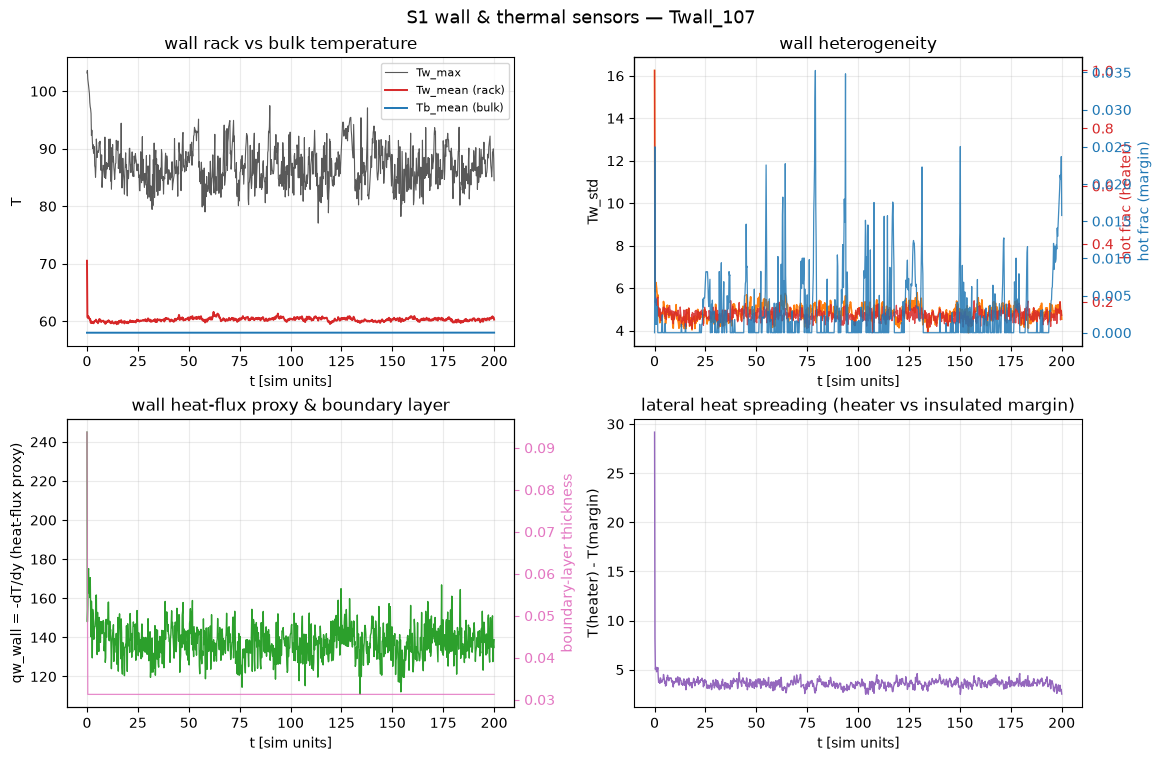

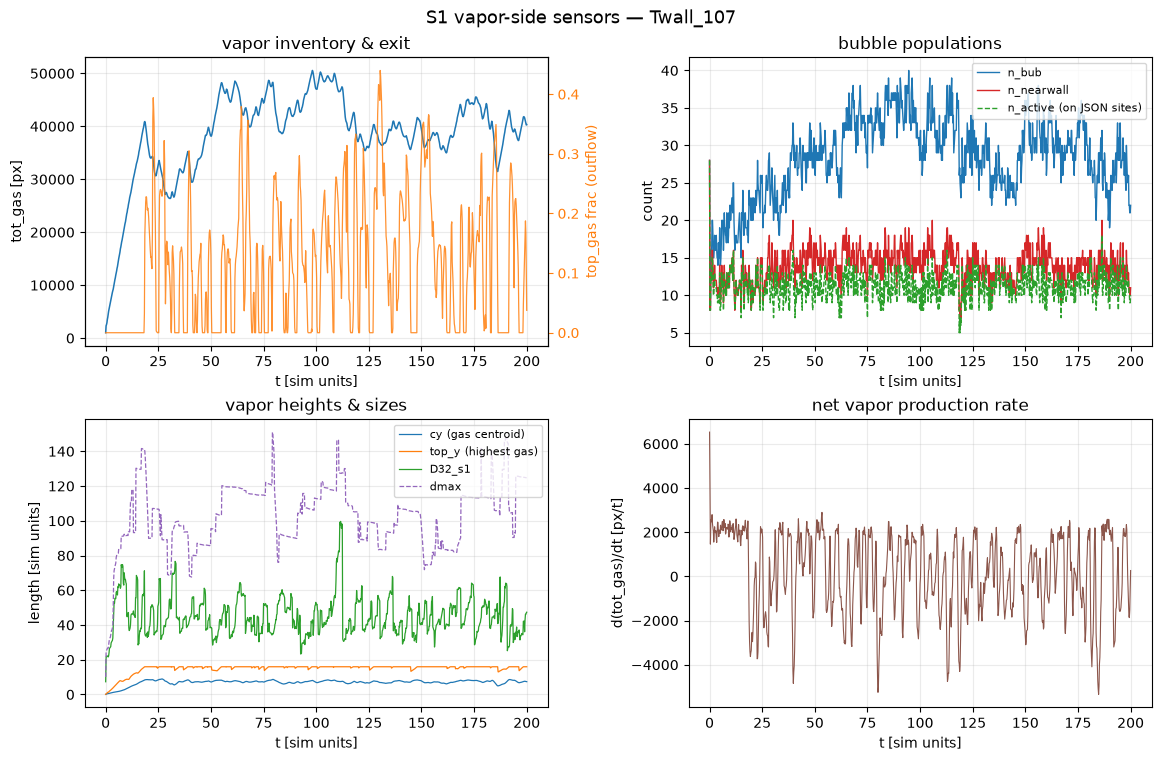

[S1] figures saved -> G:\BoilDesc\out\s1_Twall_107_wall.png, s1_Twall_107_vapor.png
[S1] next: run Cell 4 (space-time views + nucleation fidelity)


In [3]:
# ====== S1 CELL 3 / 5 — time-series view of the sensor panel =================
assert "P" in globals(), "[S1] run Cell 2 first"
t, S, TH = P["t"], P["SENS"], P["TH"]

def _twin(ax, x, y, color, label):
    ax2 = ax.twinx()
    ax2.plot(x, y, color=color, lw=0.9, alpha=0.85)
    ax2.set_ylabel(label, color=color)
    ax2.tick_params(axis="y", colors=color)
    return ax2

# ---------- wall & thermal sensors --------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(11.5, 7.5), constrained_layout=True)
a = axs.ravel()
a[0].plot(t, S["Tw_max"],  color="0.35", lw=0.8,  label="Tw_max")
a[0].plot(t, S["Tw_mean"], color="C3",   lw=1.4,  label="Tw_mean (rack)")
a[0].plot(t, S["Tb_mean"], color="C0",   lw=1.4,  label="Tb_mean (bulk)")
a[0].set_ylabel("T"); a[0].legend(loc="upper right", fontsize=8)
a[0].set_title("wall rack vs bulk temperature")

a[1].plot(t, S["Tw_std"], color="C1", lw=1.2)
a[1].set_ylabel("Tw_std")
_twin(a[1], t, S["Tw_hot_H"], "C3", "hot frac (heater)")
_twin(a[1], t, S["Tw_hot_M"], "C0", "hot frac (margin)")
a[1].set_title("wall heterogeneity")

a[2].plot(t, S["qw_wall"], color="C2", lw=1.0)
a[2].set_ylabel("qw_wall = -dT/dy (heat-flux proxy)")
_twin(a[2], t, S["bl_thick"], "C6", "boundary-layer thickness")
a[2].set_title("wall heat-flux proxy & boundary layer")

a[3].plot(t, S["Tw_HM_diff"], color="C4", lw=1.0)
a[3].set_ylabel("T(heater) - T(margin)")
a[3].set_title("lateral heat spreading (heater vs insulated margin)")

for ax in a:
    ax.set_xlabel("t [sim units]"); ax.grid(alpha=0.25)
fig.suptitle(f"S1 wall & thermal sensors — {TEST}", fontsize=13)
fig.savefig(os.path.join(OUT_DIR, f"s1_{TEST}_wall.png"), dpi=150)
plt.show()

# ---------- vapor-side sensors -------------------------------------------------
fig, axs = plt.subplots(2, 2, figsize=(11.5, 7.5), constrained_layout=True)
a = axs.ravel()
a[0].plot(t, S["tot_gas"], color="C0", lw=1.1)
a[0].set_ylabel("tot_gas [px]")
_twin(a[0], t, S["top_gas"], "C1", "top_gas frac (outflow)")
a[0].set_title("vapor inventory & exit")

a[1].plot(t, S["n_bub"],  color="C0", lw=1.0, label="n_bub")
a[1].plot(t, S["n_near"], color="C3", lw=1.0, label="n_nearwall")
a[1].plot(t, S["n_active"], color="C2", lw=1.0, ls="--", label="n_active (on JSON sites)")
a[1].set_ylabel("count"); a[1].legend(loc="upper right", fontsize=8)
a[1].set_title("bubble populations")

a[2].plot(t, P["FACTS"]["cy"],  color="C0", lw=0.9, label="cy (gas centroid)")
a[2].plot(t, P["FACTS"]["top"], color="C1", lw=0.9, label="top_y (highest gas)")
a[2].plot(t, TH[:, 2 * N_SECTIONS], color="C2", lw=0.9, label="D32_s1")
a[2].plot(t, P["FACTS"]["dmax"],   color="C4", lw=0.9, ls="--", label="dmax")
a[2].set_ylabel("length [sim units]"); a[2].legend(loc="upper right", fontsize=8)
a[2].set_title("vapor heights & sizes")

a[3].plot(t, S["dgas_dt"], color="C5", lw=0.8)
a[3].set_ylabel("d(tot_gas)/dt [px/t]")
a[3].set_title("net vapor production rate")

for ax in a:
    ax.set_xlabel("t [sim units]"); ax.grid(alpha=0.25)
fig.suptitle(f"S1 vapor-side sensors — {TEST}", fontsize=13)
fig.savefig(os.path.join(OUT_DIR, f"s1_{TEST}_vapor.png"), dpi=150)
plt.show()
print(f"[S1] figures saved -> {OUT_DIR}{os.sep}s1_{TEST}_wall.png, s1_{TEST}_vapor.png")
print("[S1] next: run Cell 4 (space-time views + nucleation fidelity)")

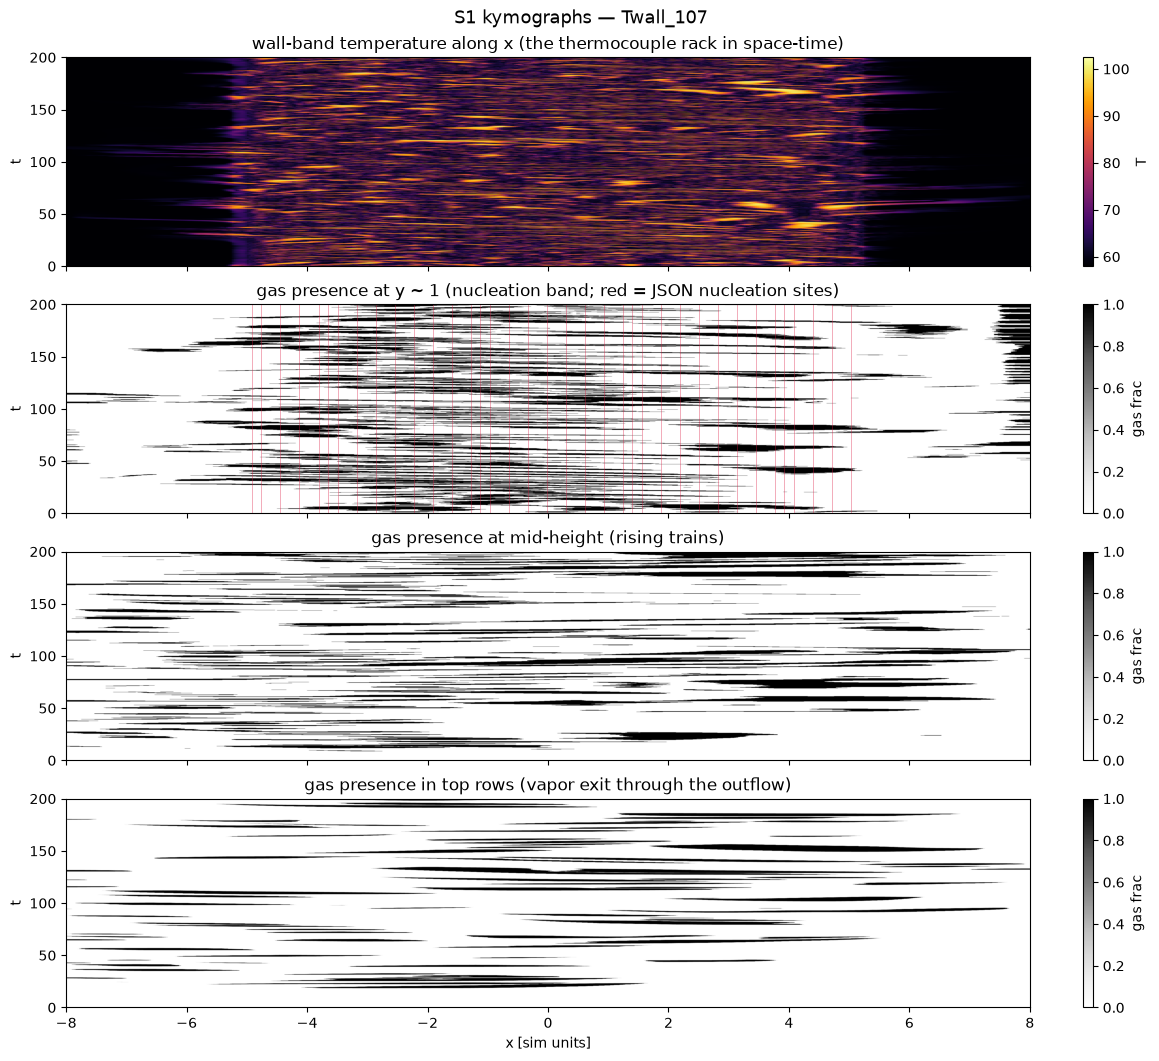

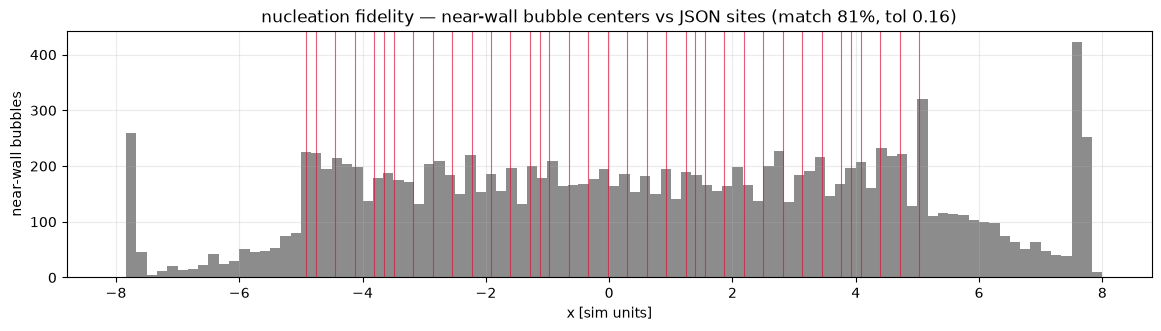

[S1] nucleation fidelity: 81% of near-wall bubble centers sit within 0.16 of a JSON site
[S1] next: run Cell 5 (summary, trend audit, save panel)


In [4]:
# ====== S1 CELL 4 / 5 — space-time views + nucleation fidelity ================
assert "P" in globals(), "[S1] run Cell 2 first"
M, t = P["meta"], P["t"]

fig, axs = plt.subplots(4, 1, figsize=(11.5, 10.5), constrained_layout=True,
                        sharex=True)
ext = [M["x_min"], M["x_max"], t[0], t[-1]]

im0 = axs[0].imshow(P["wall"].astype(np.float64).mean(axis=1), origin="lower",
                    aspect="auto", extent=ext, cmap="inferno")
plt.colorbar(im0, ax=axs[0], label="T")
axs[0].set_ylabel("t")
axs[0].set_title("wall-band temperature along x (the thermocouple rack in space-time)")

im1 = axs[1].imshow(P["gl"], origin="lower", aspect="auto", extent=ext,
                    cmap="Greys", vmin=0, vmax=1)
plt.colorbar(im1, ax=axs[1], label="gas frac")
axs[1].set_ylabel("t")
axs[1].set_title("gas presence at y ~ 1 (nucleation band; red = JSON nucleation sites)")
for x_ in P["NUC_X"]:
    axs[1].axvline(x_, color="crimson", lw=0.5, alpha=0.5)

im2 = axs[2].imshow(P["gm"], origin="lower", aspect="auto", extent=ext,
                    cmap="Greys", vmin=0, vmax=1)
plt.colorbar(im2, ax=axs[2], label="gas frac")
axs[2].set_ylabel("t")
axs[2].set_title("gas presence at mid-height (rising trains)")

im3 = axs[3].imshow(P["gtop"], origin="lower", aspect="auto", extent=ext,
                    cmap="Greys", vmin=0, vmax=1)
plt.colorbar(im3, ax=axs[3], label="gas frac")
axs[3].set_ylabel("t"); axs[3].set_xlabel("x [sim units]")
axs[3].set_title("gas presence in top rows (vapor exit through the outflow)")

fig.suptitle(f"S1 kymographs — {TEST}", fontsize=13)
fig.savefig(os.path.join(OUT_DIR, f"s1_{TEST}_kymo.png"), dpi=150)
plt.show()

# ---------- nucleation fidelity: observed vs JSON sites ------------------------
fig, ax = plt.subplots(figsize=(11.5, 3.2), constrained_layout=True)
match = float("nan")
if len(P["cx_near"]):
    ax.hist(P["cx_near"], bins=96, range=(M["x_min"], M["x_max"]),
            color="0.55", edgecolor="none")
    if len(P["NUC_X"]):
        match = float(np.mean([np.min(np.abs(P["NUC_X"] - c)) <= SITE_TOL
                               for c in P["cx_near"]]))
        ttl = (f"nucleation fidelity — near-wall bubble centers vs JSON sites "
               f"(match {match:.0%}, tol {SITE_TOL:.2f})")
    else:
        ttl = "near-wall bubble centers (no JSON site list to compare)"
else:
    ttl = "no near-wall bubbles captured"
for x_ in P["NUC_X"]:
    ax.axvline(x_, color="crimson", lw=0.8, alpha=0.7)
ax.set_xlabel("x [sim units]"); ax.set_ylabel("near-wall bubbles")
ax.set_title(ttl); ax.grid(alpha=0.25)
fig.savefig(os.path.join(OUT_DIR, f"s1_{TEST}_nucfidelity.png"), dpi=150)
plt.show()
if np.isfinite(match):
    print(f"[S1] nucleation fidelity: {match:.0%} of near-wall bubble centers sit "
          f"within {SITE_TOL:.2f} of a JSON site")
else:
    print("[S1] nucleation fidelity: no site list or no near-wall bubbles")
print("[S1] next: run Cell 5 (summary, trend audit, save panel)")

In [5]:
# ====== S1 CELL 6 / 6 — all results of Cells 1-5, collected into clear tables ==
# Additive & idempotent: re-run any time; nothing is recomputed from the HDF5.
# Tables are built from the kernel state left by Cells 1-5 and — after a kernel
# restart — from the panel Cell 5 saved (s1_<TEST>.npz under OUT_DIR).
# With pandas you get pretty HTML tables; without pandas, fixed-width text.
import glob, json, os
import numpy as np
from scipy.stats import spearmanr

try:
    import pandas as _pd
except Exception:
    _pd = None

# ---- guards: fill only what is missing (never override user settings) ---------
try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
try: OUT_DIR
except NameError: OUT_DIR = os.path.join(DATA_ROOT, "out")
_W = globals().get("W_", 78)
W_ = int(_W) if isinstance(_W, (int, float)) else 78

def _f(v):
    try: return float(v)
    except (TypeError, ValueError): return float("nan")

def _g(v, fmt="%.4g"):
    v = _f(v)
    return "n/a" if not np.isfinite(v) else fmt % v

def _pc(v):
    v = _f(v)
    return "n/a" if not np.isfinite(v) else f"{v:.0%}"

def _stats(v):
    """(min, mean, std, max, coverage) as strings; warning-free on all-NaN."""
    v = np.asarray(v, float); m = np.isfinite(v)
    if not m.any():
        return ("n/a", "n/a", "n/a", "n/a", "0%")
    s = v[m]
    return (_g(s.min()), _g(s.mean()), _g(s.std()), _g(s.max()),
            f"{100.0 * m.sum() / max(v.size, 1):.0f}%")

# ---- panel access: kernel ALL_S1 first, then the npz Cell 5 saved -------------
def _npz_meta(label):
    p = os.path.join(OUT_DIR, f"s1_{label}.npz")
    if not os.path.exists(p):
        return None
    try:
        with np.load(p, allow_pickle=False) as z:
            return json.loads(str(z["meta"]))
    except Exception:
        return None

def _panel(label):
    """(P-like dict, source) for one label: kernel ALL_S1, else s1_<label>.npz."""
    _A = globals().get("ALL_S1")
    if isinstance(_A, dict) and label in _A:
        return _A[label], "kernel"
    p = os.path.join(OUT_DIR, f"s1_{label}.npz")
    if os.path.exists(p):
        try:
            with np.load(p, allow_pickle=False) as z:
                meta = json.loads(str(z["meta"]))
                P_ = {"label": label,
                      "t": np.asarray(z["t"], float),
                      "TH": np.asarray(z["TH"], float),
                      "SENS": {k[3:]: np.asarray(z[k], float)
                               for k in z.files if k.startswith("s__")},
                      "FACTS": {k[3:]: np.asarray(z[k], float)
                                for k in z.files if k.startswith("f__")},
                      "cx_near": (np.asarray(z["cx_near"], float).ravel()
                                  if "cx_near" in z.files else np.array([])),
                      "NUC_X": (np.asarray(z["NUC_X"], float).ravel()
                                if "NUC_X" in z.files else np.array([])),
                      "wall": (np.asarray(z["wall"], float)
                               if "wall" in z.files else None),
                      "TrowL": (np.asarray(z["TrowL"], float)
                                if "TrowL" in z.files else None),
                      "meta": meta}
                return P_, "disk (npz saved by Cell 5)"
        except Exception as e:
            print(f"[S1] warning: could not read {p} ({e})")
    return None, None

_Pk = globals().get("P")
if isinstance(_Pk, dict) and "TH" in _Pk and "SENS" in _Pk:
    _P, _SRC = _Pk, "kernel (state of Cells 1-5)"
else:
    _P, _SRC = _panel(TEST)
if _P is None:
    _A = globals().get("ALL_S1")
    if isinstance(_A, dict) and len(_A) == 1:
        _P, _SRC = _panel(next(iter(_A)))
if _P is None:
    _found = sorted(glob.glob(os.path.join(OUT_DIR, "s1_*.npz")))
    if _found:
        _P, _SRC = _panel(os.path.basename(_found[0])[3:-4])
assert _P is not None, (
    "[S1] Cell 6 found no S1 results: neither the state of Cells 1-5 in this "
    f"kernel nor a saved s1_*.npz under {OUT_DIR}. Run Cells 1-5 first (Cell 5 "
    "saves the panel), then re-run this cell.")

# ---- unpack the active panel ---------------------------------------------------
_t   = np.asarray(_P["t"], float)
_TH  = np.asarray(_P["TH"], float)
_S   = {k: np.asarray(v, float) for k, v in _P["SENS"].items()}
_Ff  = {k: np.asarray(v, float) for k, v in _P["FACTS"].items()}
_M   = _P["meta"]
_N   = int(_t.size)
_NP  = int(_TH.shape[1])
_LAB = str(_P.get("label", TEST))

NAMES_S1 = globals().get("NAMES_S1")
SHORT_S1 = globals().get("SHORT_S1")
if not isinstance(NAMES_S1, list) or len(NAMES_S1) != _NP \
        or not isinstance(SHORT_S1, dict) or len(SHORT_S1) < _NP:
    _K = _NP // 4
    NAMES_S1 = [f"{f_}_s{k + 1}" for f_ in ("alpha", "Tmean", "D32", "fhot")
                for k in range(_K)]
    _SFC = dict(zip(("alpha", "Tmean", "D32", "fhot"), "aTDh"))
    SHORT_S1 = {f"{f_}_s{k + 1}": f"{_SFC[f_]}{k + 1}"
                for f_ in ("alpha", "Tmean", "D32", "fhot") for k in range(_K)}

def _cond_of(label, src, Pd):
    """COND dict for one panel: kernel COND (if it matches), else saved meta."""
    c = {}
    if src.startswith("kernel") and label == TEST \
            and isinstance(globals().get("COND"), dict):
        c = {k: _f(v) for k, v in globals()["COND"].items()}
    mc = (Pd.get("meta") or {}).get("COND") or {}
    if not mc:
        mc = (_npz_meta(label) or {}).get("COND") or {}
    for k, v in mc.items():
        if k not in c or not np.isfinite(c[k]):
            c[k] = _f(v)
    return c

def _site_tol(nx):
    nx = np.asarray(nx, float).ravel()
    if len(nx) > 2:
        return float(np.median(np.diff(np.sort(nx))) / 2.0)
    return 0.15

def _fidelity(Pd):
    cx = np.asarray(Pd.get("cx_near", []), float).ravel()
    nx = np.asarray(Pd.get("NUC_X", []), float).ravel()
    if len(cx) and len(nx):
        tol = _site_tol(nx)
        return float(np.mean([np.min(np.abs(nx - c)) <= tol for c in cx]))
    return float("nan")

def _live_cnt(TH_):
    TH_ = np.asarray(TH_, float)
    c = 0
    for j in range(TH_.shape[1]):
        m = np.isfinite(TH_[:, j])
        if m.sum() and float(np.std(TH_[m, j])) > 1e-12:
            c += 1
    return c

def _mean_of(Sd, key, fmt="%.4g"):
    v = np.asarray(Sd.get(key, [np.nan]), float)
    m = np.isfinite(v)
    return _g(v[m].mean(), fmt) if m.any() else "n/a"

_C6C   = _cond_of(_LAB, _SRC, _P)
_WT    = _f(_C6C.get("wallTemp"))
_NUCX  = np.asarray(_P.get("NUC_X", []), float).ravel()
_STOL  = _site_tol(_NUCX)
_CX    = np.asarray(_P.get("cx_near", []), float).ravel()
_MATCH = _fidelity(_P)
_NMATCH = int(round(_MATCH * len(_CX))) if np.isfinite(_MATCH) else 0
_NUCW  = _f(globals().get("NUC_WAIT"))
_NR    = globals().get("NUC_R")
_NUCR  = np.asarray(_NR, float).ravel() if _NR is not None else np.array([])
_HX0, _HX1 = _f(globals().get("HX0")), _f(globals().get("HX1"))
_DTSMPL = _f(_M.get("dt_sample"))
_TAU    = _f(_M.get("tau"))
_TLVL   = _f(globals().get("TAU_LEVEL"))
_TDEF   = "TAU_LEVEL" not in globals()
if not np.isfinite(_TLVL):
    _TLVL, _TDEF = 0.75, True

# temperature extent: Cell 2's field stats if still in the kernel, else wall band
_FMIN, _FMAX, _FMEAN = _f(globals().get("fmin")), _f(globals().get("fmax")), float("nan")
_FS = _f(globals().get("fsum"))
if np.isfinite(_FS) and _N:
    _FMEAN = _FS / _N
_SRC_EXT = "field extremes kept by Cell 2"
if not (np.isfinite(_FMIN) and np.isfinite(_FMAX)) and _P.get("wall") is not None:
    _wb = np.asarray(_P["wall"], float)
    _FMIN, _FMAX, _FMEAN = float(_wb.min()), float(_wb.max()), float(_wb.mean())
    _SRC_EXT = "wall band only (kernel restarted; full field not retained)"

# empirical Tsat (Cell 2 definition), recomputed if the kernel value is gone
_TSE = _f(globals().get("_Tsat"))
if not np.isfinite(_TSE) and _P.get("TrowL") is not None and _M.get("H"):
    _up = np.asarray(_P["TrowL"], float)[:, int(_M["H"]) // 2:]
    _okf = np.isfinite(_up)
    if _okf.any():
        _TSE = float(np.quantile(_up[_okf], 0.01))

_SCALE_OK = (np.isfinite(_WT) and np.isfinite(_FMAX)
             and abs(_FMAX - _WT) <= 0.05 * abs(_WT))
if np.isfinite(_NUCW) and np.isfinite(_DTSMPL):
    _ADEQ = "OK" if _DTSMPL <= _NUCW else "COARSE (nucleation cycles aliased)"
else:
    _ADEQ = "n/a (no nucWaitTime)"

# theta live/dead (same rule as Cells 2 & 5, but warning-free)
_LIVE, _DEAD = [], []
for _j in range(_NP):
    _m = np.isfinite(_TH[:, _j])
    if _m.sum() and float(np.std(_TH[_m, _j])) > 1e-12:
        _LIVE.append(_j)
    else:
        _DEAD.append(_j)
_LIVESET = set(_LIVE)
_DEADS = [SHORT_S1.get(NAMES_S1[_j], NAMES_S1[_j]) for _j in _DEAD]
_STRUCT = bool(_DEADS) and set(_DEADS) <= {"h2", "h3", "h4", "h5"}

# trend audit (same rule as Cell 5): Spearman rho vs t on every usable series
def _rho(v):
    m = np.isfinite(v)
    if m.sum() >= 5 and float(np.std(v[m])) > 1e-12:
        return float(spearmanr(v[m], _t[m])[0])
    return None

_TR, _NSER = [], 0
for _k in [k for k in _S if k != "t"] + list(_Ff):
    _NSER += 1
    _r = _rho(np.asarray(_S.get(_k, _Ff.get(_k)), float))
    if _r is not None:
        _TR.append((abs(_r), _k, _r))
for _j in _LIVE:
    _NSER += 1
    _r = _rho(_TH[:, _j])
    if _r is not None:
        _TR.append((abs(_r), "th:" + SHORT_S1[NAMES_S1[_j]], _r))
_TR.sort(key=lambda _x: (-_x[0], _x[1]))
_NSKIP = _NSER - len(_TR)
_NCLK  = sum(1 for _a, _, _ in _TR if _a >= 0.95)
_TOP3  = ", ".join(_k for _, _k, _ in _TR[:3])

# ---- table renderer ------------------------------------------------------------
def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    elif _pd is not None:
        _df = _pd.DataFrame(rows, columns=cols).set_index(cols[0])
        try:
            display(_df)                                  # noqa: F821 (Jupyter)
        except NameError:
            print(_df.to_string())
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0 else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

print("=" * W_)
print(f"S1 CELL 6 - RESULTS OF ALL CELLS, IN CLEAR TABLES - {_LAB}")
print(f"panel source: {_SRC}   |   renderer: {'pandas' if _pd is not None else 'text'}")
print("=" * W_)

# ---- TABLE 1: run status -------------------------------------------------------
def _exists(*fns):
    return all(os.path.exists(os.path.join(OUT_DIR, fn)) for fn in fns)

_csvp = os.path.join(OUT_DIR, f"s1_{_LAB}.csv")
_CSVD = "panel not saved yet (re-run Cell 5)"
if os.path.exists(_csvp):
    try:
        _ls = open(_csvp).read().strip().splitlines()
        if len(_ls) >= 2:
            _CSVD = f"{len(_ls) - 1} rows x {len(_ls[0].split(','))} cols (s1_{_LAB}.csv)"
        elif _ls:
            _CSVD = f"{max(len(_ls) - 1, 0)} rows (s1_{_LAB}.csv)"
    except Exception as e:
        _CSVD = f"csv unreadable ({e})"

_MC     = _M.get("COND") or {}
_MC_HAS = any(v is not None for v in _MC.values())
_rows1 = [
    ["Cell 1", "condition header: JSON sidecar, heater span, nucleation sites",
     "done" if np.isfinite(_WT) else "absent",
     (f"sidecar parsed (wallTemp {_g(_WT, '%.1f')})" if np.isfinite(_WT)
      else ("sidecar values cached in the npz Cell 5 saved" if _MC_HAS
            else "no JSON sidecar for this file - condition rows show n/a"))],
    ["Cell 2", "panel build: theta + facts + virtual sensors (one streaming pass)",
     "done",
     f"{_N} sampled frames x {_NP} theta + {len(_S) - 1} sensors + "
     f"{len(_Ff)} facts  [{_SRC}]"],
    ["Cell 3", "time-series figures (wall & thermal / vapor side)",
     "done" if _exists(f"s1_{_LAB}_wall.png", f"s1_{_LAB}_vapor.png") else "not found",
     f"s1_{_LAB}_wall.png, s1_{_LAB}_vapor.png"],
    ["Cell 4", "kymographs + nucleation fidelity histogram",
     "done" if _exists(f"s1_{_LAB}_kymo.png", f"s1_{_LAB}_nucfidelity.png") else "not found",
     (f"match {_pc(_MATCH)} (tol {_STOL:.2f})" if np.isfinite(_MATCH)
      else ("near-wall bubbles captured, but no JSON site list" if len(_CX)
            else "no near-wall bubbles captured"))],
    ["Cell 5", "summary, trend audit, panel saved to disk",
     "done" if os.path.exists(os.path.join(OUT_DIR, f"s1_{_LAB}.npz")) else "not found",
     _CSVD],
]
_render("TABLE 1 - RUN STATUS: which cell produced what",
        ["cell", "what it produced", "status", "artifact / evidence"], _rows1,
        "Figures and npz/csv are checked on disk in OUT_DIR; 'not found' just "
        "means re-run that cell - the tables below come from the panel either way.")

# ---- TABLE 2: condition header (Cell 1 + grid from Cell 2) ---------------------
_STRv = globals().get("STRIDE_S1")
if isinstance(_STRv, (int, np.integer)) and not isinstance(_STRv, bool):
    _STR = str(int(_STRv))
else:
    _TnM = _f(_M.get("Tn"))
    _STR = (f"~{int(round(_TnM / _N))} (inferred)" if np.isfinite(_TnM) and _N
            else "n/a")
_nparts = []
if len(_NUCR):
    _nparts.append(f"seed r {_g(float(np.median(_NUCR)))}")
_nparts += [f"wait {_g(_NUCW, '%g')}", f"match tol {_STOL:.2f}"]
_rows2 = [
    ["heater wallTemp", _g(_WT, "%.1f"),
     "the only true per-file sensor scalar (JSON heater.wallTemp)"],
    ["T_sat (sidecar)",
     ("absent" if not np.isfinite(_C6C.get("T_sat", np.nan)) else _g(_C6C["T_sat"])),
     ("no T_sat in the sidecar -> scale resolved empirically (Table 3)"
      if not np.isfinite(_C6C.get("T_sat", np.nan)) else "from the JSON sidecar")],
    ["time window", f"{_g(_C6C.get('t0'), '%g')} -> {_g(_C6C.get('t1'), '%g')}",
     f"dt {_g(_C6C.get('dt'), '%g')} (JSON simulation settings)"],
    ["nondim groups",
     f"Pr {_g(_C6C.get('Pr'), '%g')} | 1/Re {_g(_C6C.get('invRe'), '%g')}"
     f" | St {_g(_C6C.get('St'), '%g')} | grav_y {_g(_C6C.get('gravy'), '%g')}",
     "solver-native dimensionless groups"],
    ["domain",
     f"x {_g(_M.get('x_min'), '%g')}..{_g(_M.get('x_max'), '%g')}"
     f"   y {_g(_M.get('y_min'), '%g')}..{_g(_M.get('y_max'), '%g')}",
     "from HDF5 x/y datasets (or JSON domain fallback)"],
    ["grid", f"{_g(_M.get('Tn'), '%i')} frames x {_M.get('H')} x {_M.get('W')}",
     f"dx {_g(_M.get('dx'), '%.4g')}, dy {_g(_M.get('dy'), '%.4g')}"
     + ("" if abs(_f(_M.get("dx")) - _f(_M.get("dy"))) < 1e-12
        else "  [non-square cells]")],
    ["heater span",
     (f"x {_g(_HX0, '%g')}..{_g(_HX1, '%g')}"
      if np.isfinite(_HX0) and np.isfinite(_HX1) else "n/a"),
     (f"width {_g(_HX1 - _HX0, '%g')} = "
      f"{100 * (_HX1 - _HX0) / max(_f(_M.get('x_max')) - _f(_M.get('x_min')), 1e-12):.1f}"
      "% of domain, at y~0; the |x| margins are insulated wall"
      if np.isfinite(_HX0) and np.isfinite(_HX1)
      else "not retained in the saved panel - re-run Cell 1 in the kernel")],
    ["nucleation sites", f"{len(_NUCX)}", "; ".join(_nparts)],
    ["sampling", f"{_N} of {_g(_M.get('Tn'), '%i')} frames",
     f"stride {_STR}; dt_sample {_g(_DTSMPL, '%.3g')} vs nucWaitTime "
     f"{_g(_NUCW, '%g')} -> {_ADEQ}"],
    ["tau (hot threshold)", _g(_TAU),
     f"P{int(round(_TLVL * 100))} of the wall band, full width"
     + (" [default level]" if _TDEF else "")],
]
_render("TABLE 2 - CONDITION HEADER (Cell 1: JSON sidecar; grid from Cell 2)",
        ["parameter", "value", "note"], _rows2)

# ---- TABLE 3: temperature scale & calibration (Cell 2) -------------------------
if _SCALE_OK:
    _sc_val, _sc_note = "yes", (
        f"|T_max - wallTemp| <= 5% -> one scale; empirical superheat ~ "
        f"{_g(_WT - _TSE, '%.1f')} (wallTemp - bulk P1)")
elif np.isfinite(_WT) and np.isfinite(_FMAX):
    _sc_val, _sc_note = "no", ("field scale differs from the sidecar; units are "
                               "treated as solver-native")
else:
    _sc_val, _sc_note = "n/a", "wallTemp or field extent unknown (no sidecar / restart)"
_rows3 = [
    ["T min", _g(_FMIN), _SRC_EXT],
    ["T mean", _g(_FMEAN), _SRC_EXT],
    ["T max", _g(_FMAX), _SRC_EXT],
    ["bulk P1 (empirical Tsat)", _g(_TSE),
     "1st percentile of liquid-only heater-column row-mean T, upper half (Cell 2)"],
    ["sidecar wallTemp", _g(_WT, "%.1f"), "JSON heater.wallTemp"],
    ["scale agreement", _sc_val, _sc_note],
    ["tau", _g(_TAU), "hot-spot threshold behind Tw_hot_* and f_hot (Cell 2)"],
]
_render("TABLE 3 - TEMPERATURE SCALE & CALIBRATION (Cell 2)",
        ["quantity", "value", "note"], _rows3)

# ---- TABLE 4: theta indicators -------------------------------------------------
_rows4 = []
for _j in range(_NP):
    _nm = NAMES_S1[_j]
    _fam, _sec = _nm.rsplit("_s", 1)
    if _j in _LIVESET:
        _mn, _me, _sd, _mx, _ = _stats(_TH[:, _j])
        _st = "live"
    else:
        _mn = _me = _sd = _mx = "n/a"
        _st = "dead"
    _rows4.append([_nm, SHORT_S1.get(_nm, "-"), _fam, _sec, _st,
                   f"{int(np.isfinite(_TH[:, _j]).sum())}", _mn, _me, _sd, _mx])
_note4 = f"{len(_LIVE)}/{_NP} live"
if _DEADS:
    _note4 += f"; dead: {' '.join(_DEADS)}"
if _STRUCT:
    _note4 += ("  -> structural: f_hot is a wall-band statistic, only section 1 "
               "is defined; h2..h5 are dead by construction, not data failures")
elif _DEADS:
    _note4 += "  -> unexpected: check the Cell 2 report for these columns"
_render("TABLE 4 - THETA INDICATORS: HEALTH & STATISTICS (Cells 2 + 5)",
        ["indicator", "short", "family", "section", "status", "n_finite",
         "mean", "std", "min", "max"], _rows4, _note4)

# ---- TABLE 5: virtual sensor panel ---------------------------------------------
_GRP = {
    "Tw_mean": ("wall thermal", "T"), "Tw_max": ("wall thermal", "T"),
    "Tw_std": ("wall thermal", "T"), "Tw_hot_raw": ("wall thermal", "frac"),
    "Tw_hot_H": ("wall thermal", "frac"), "Tw_hot_M": ("wall thermal", "frac"),
    "Tw_HM_diff": ("wall thermal", "T"),
    "Tw_cov": ("wall vapor", "frac"), "Tw_cov_H": ("wall vapor", "frac"),
    "qw_wall": ("heat flux", "T/len"), "bl_thick": ("heat flux", "len"),
    "Tb_mean": ("bulk", "T"), "Tb_std": ("bulk", "T"),
    "tot_gas": ("vapor side", "px"), "dgas_dt": ("vapor side", "px/t"),
    "top_gas": ("vapor side", "frac"),
    "n_bub": ("populations", "count"), "n_near": ("populations", "count"),
    "n_active": ("populations", "count"),
}
_rows5 = []
for _k in [k for k in _S if k != "t"]:
    _gr, _un = _GRP.get(_k, ("(other)", "-"))
    _mn, _me, _sd, _mx, _cv = _stats(_S[_k])
    _rows5.append([_k, _gr, _un, _mn, _me, _sd, _mx, _cv])
_render("TABLE 5 - VIRTUAL SENSOR PANEL: STATISTICS (Cells 2 + 5)",
        ["sensor", "group", "unit", "min", "mean", "std", "max", "coverage"],
        _rows5,
        "Thermocouple-like sensors use liquid-contact pixels only. 'n/a' rows = "
        "all-NaN (e.g. no insulated margin on fallback files). Coverage = share "
        "of sampled frames with a valid value.")

# ---- TABLE 6: field facts ------------------------------------------------------
_FMI = {
    "tot_gas": ("vapor inventory", "px"),
    "dmax": ("largest bubble equiv diameter", "len"),
    "n_bub": ("bubble count (blobs >= MIN_BLOB_PX)", "count"),
    "cx": ("vapor centroid x", "pos"), "cy": ("vapor centroid y", "pos"),
    "iface": ("interface length (eroded-boundary px)", "px"),
    "top": ("highest vapor y", "pos"),
}
_rows6 = [[_k, _FMI.get(_k, ("?", "-"))[0], _FMI.get(_k, ("?", "-"))[1],
           *_stats(_Ff[_k])[:4]] for _k in _Ff]
_render("TABLE 6 - FIELD FACTS: STATISTICS (Cells 2 + 5)",
        ["fact", "meaning", "unit", "min", "mean", "std", "max"], _rows6)

# ---- TABLE 7: trend audit (the S2 confound landscape) --------------------------
_rows7 = [[_k, f"{_r:+.2f}", f"{_a:.2f}",
           ("clock-like" if _a >= 0.95 else "strong drift" if _a >= 0.80
            else "mild drift" if _a >= 0.50 else "-")]
          for _a, _k, _r in _TR[:15]]
_NREST = max(len(_TR) - 15, 0)
_next7 = f"{_TR[15][0]:.2f}" if len(_TR) > 15 else "-"
_render("TABLE 7 - TREND AUDIT: SPEARMAN rho vs t (Cell 5) - the S2 confound landscape",
        ["series", "rho_t", "|rho_t|", "drift flag"], _rows7,
        f"+{_NREST} more series (next |rho| = {_next7}); {_NSKIP} skipped "
        "(constant or <5 valid samples). Clock-like series are confounded with "
        "time: S2 must report partial correlations given t on the top pairs.")

# ---- TABLE 8: nucleation fidelity (Cells 1 + 4) --------------------------------
if np.isfinite(_MATCH):
    _fnote = ("observed nucleation reproduces the JSON site map" if _MATCH >= 0.8
              else "partial agreement with the site map" if _MATCH >= 0.5
              else "weak agreement with the site map")
elif len(_CX):
    _fnote = "no JSON site list to compare against"
else:
    _fnote = "no near-wall bubbles captured"
_rows8 = [
    ["near-wall bubble centers", f"{len(_CX)}",
     "blobs whose lowest row < NEARWALL_ROWS (Cells 2 + 4)"],
    ["JSON nucleation sites", f"{len(_NUCX)}",
     "heater.nuc_sites_x in the sidecar (Cell 1)"],
    ["matched centers", (f"{_NMATCH}" if np.isfinite(_MATCH) else "n/a"),
     f"within match tol {_STOL:.2f} of a site"],
    ["match fraction", _pc(_MATCH), _fnote],
]
_render("TABLE 8 - NUCLEATION FIDELITY (Cells 1 + 4)",
        ["quantity", "value", "note"], _rows8)

# ---- TABLE 9: panels on record -------------------------------------------------
_A9 = globals().get("ALL_S1")
_labels = list(_A9.keys()) if isinstance(_A9, dict) else []
_labels += [os.path.basename(p)[3:-4]
            for p in sorted(glob.glob(os.path.join(OUT_DIR, "s1_*.npz")))]
_labels = sorted(set(_labels))
_rows9 = []
for _lb in _labels:
    _Pd, _srcd = _panel(_lb)
    if _Pd is None:
        continue
    _cd = _cond_of(_lb, _srcd, _Pd)
    _rows9.append([
        _lb, _srcd.split(" ")[0], _g(_cd.get("wallTemp"), "%.1f"),
        str(len(_Pd["t"])),
        _mean_of(_Pd["SENS"], "Tw_mean"), _mean_of(_Pd["SENS"], "qw_wall"),
        _mean_of(_Pd["SENS"], "tot_gas"), _mean_of(_Pd["SENS"], "n_bub", "%.2f"),
        _mean_of(_Pd["SENS"], "dgas_dt"),
        f"{_live_cnt(_Pd['TH'])}/{_Pd['TH'].shape[1]}",
        _pc(_fidelity(_Pd))])
_render("TABLE 9 - S1 PANELS ON RECORD (kernel + saved npz)",
        ["label", "source", "wallTemp", "frames", "Tw_mean", "qw_wall",
         "tot_gas", "n_bub", "dgas_dt", "live theta", "fidelity"], _rows9,
        "One row per S1 panel (kernel state + every s1_*.npz Cell 5 saved). To "
        "add a file: set TEST = 'Twall_99' in Cell 1, re-run Cells 1-5, re-run "
        "this cell. Study B (wallTemp on the x-axis) needs >= 3 files.")

# ---- takeaway ------------------------------------------------------------------
print()
print("=" * W_)
print("TAKEAWAY")
print("=" * W_)
print(f"  theta health      : {len(_LIVE)}/{_NP} live"
      + (f"; dead: {' '.join(_DEADS)}" if _DEADS else "")
      + ("  [structural: f_hot is wall-band only]" if _STRUCT else ""))
if _SCALE_OK:
    print(f"  temperature scale : field & sidecar share one scale; empirical "
          f"superheat ~ {_g(_WT - _TSE, '%.1f')}")
elif np.isfinite(_WT):
    print("  temperature scale : field differs from sidecar (solver-native units)")
if _NCLK:
    print(f"  clock risk        : {_NCLK} series with |rho_t| >= 0.95 "
          f"(top: {_TOP3}) -> S2 must partial out t")
else:
    print("  clock risk        : no clock-like series; t-confound looks mild")
if np.isfinite(_MATCH):
    print(f"  nucleation        : {_MATCH:.0%} of {len(_CX)} near-wall centers "
          f"sit on JSON sites (tol {_STOL:.2f})")
if _CSVD.startswith("panel not"):
    print("  saved panel       : not yet on disk - run Cell 5 to save it")
else:
    print(f"  saved panel       : s1_{_LAB}.npz + csv ({_CSVD})")
print()
print("[S1] Cell 6 complete. Next: S2 - sensors x indicators correlation study")
print("     (raw + partial given t, circularity flags, lagged pairs) from the "
      "saved panel.")

S1 CELL 6 - RESULTS OF ALL CELLS, IN CLEAR TABLES - Twall_107
panel source: kernel (state of Cells 1-5)   |   renderer: text

--------------------------------------------------------------------------
TABLE 1 - RUN STATUS: which cell produced what
--------------------------------------------------------------------------
cell    what it produced                                                   status     artifact / evidence
------  -----------------------------------------------------------------  ---------  ------------------------------------------------------------------------------------
Cell 1      condition header: JSON sidecar, heater span, nucleation sites       done                                                       sidecar parsed (wallTemp 107.0)
Cell 2  panel build: theta + facts + virtual sensors (one streaming pass)       done  1001 sampled frames x 20 theta + 19 sensors + 7 facts  [kernel (state of Cells 1-5)]
Cell 3                  time-series figures (wall & therma